# 02 — Target Selection

**Goal** – Decide between `log1p(play_count)` at day 7, 14, or 30, and
between an *absolute* and *relative* (creator-centred) target formulation.
Five questions are answered in sequence.

**Input** – The three raw tables + `config/default.yaml`.

**Conclusion** –
**Day 14** is the right measurement point: 100 % exact coverage (day 7 = 98.4 %;
day 30 = 35.3 %), and videos already hold a median **95.2 %** of their
day-30 play_count by then.
Day-30 under-coverage is time-based, not popularity-based (day-14 medians 623 vs
587 for covered/uncovered groups).
1 240 videos (0.59 %) have a monotonicity violation; when present the median
drop is 96 % of peak — a data-collection reset artefact.
**Relative target is strongly preferred**: 73.2 % of the variance in the
absolute `log1p(play_count_day14)` is explained by `author_id` alone (test
R² = 0.732); the relative target (subtract per-creator train median) reduces
this to 4.4 %, isolating content-driven variance.
`follower_count` at publish time (as-of join, 100 % coverage) has Spearman
ρ = 0.639 with the absolute target — it is a powerful feature, not a target
component, and confirms the scale of the creator effect.


In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess, os
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Shopska/Personalized_analysis_of_social_media.git", "repo"],
        check=True,
    )
    os.chdir("repo")
    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
        check=True,
    )
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)


In [2]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure working directory is the project root when opened from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


In [3]:
from creator_analytics.config import load_config
from creator_analytics.data import filter_creators, load_raw_table, train_test_split_by_creator
from creator_analytics.features import follower_asof_join
from creator_analytics.targets import build_target

cfg    = load_config("config/default.yaml")
RAW    = cfg["paths"]["raw_dir"]
FIGS   = Path("results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

videos        = load_raw_table(RAW, "videos")
creator_daily = load_raw_table(RAW, "creator_daily")
engagement    = load_raw_table(RAW, "engagement_daily")
print(f"videos {len(videos):,}  creator_daily {len(creator_daily):,}  engagement {len(engagement):,}")


videos 209,543  creator_daily 278,433  engagement 6,068,955


## 1. Coverage by `days_since_post`

In [4]:
total = videos["video_id"].nunique()
rows = []
for day in [0, 7, 14, 21, 28, 30]:
    exact = engagement[engagement["days_since_post"] == day]["video_id"].nunique()
    geq   = engagement[engagement["days_since_post"] >= day]["video_id"].nunique()
    rows.append({"day": day,
                 "exact_n": exact, "exact_%": round(exact / total * 100, 1),
                 "≥day_n": geq,    "≥day_%":  round(geq   / total * 100, 1)})

display(pd.DataFrame(rows).set_index("day"))

# tracking window per video
max_day = engagement.groupby("video_id")["days_since_post"].max()
n_days  = engagement.groupby("video_id")["days_since_post"].nunique()
print(f"\nDistinct days tracked per video: "
      f"median={n_days.median():.0f}  p5={n_days.quantile(0.05):.0f}  p95={n_days.quantile(0.95):.0f}")


,exact_n,exact_%,≥day_n,≥day_%
day,,,,
0,157065,75.0,209543,100.0
7,206216,98.4,209543,100.0
14,209543,100.0,209543,100.0
21,195654,93.4,209452,100.0
28,193465,92.3,198733,94.8
30,73940,35.3,73940,35.3



Distinct days tracked per video: median=30  p5=22  p95=31


> **Key observation**: day 14 is the *only* day with 100 % exact coverage.
> Day 30 is 35.3 %; day 7 is 98.4 %.  Use the table above to compare.


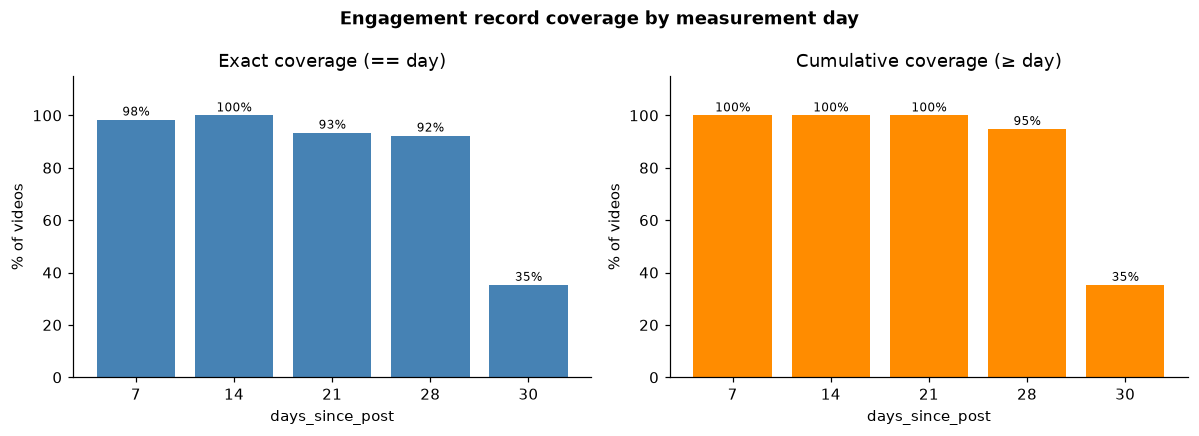

In [5]:
cov_df   = pd.DataFrame(rows)
sel_days = [7, 14, 21, 28, 30]
sub      = cov_df[cov_df["day"].isin(sel_days)].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title, color in [
    (axes[0], "exact_%", "Exact coverage (== day)", "steelblue"),
    (axes[1], "≥day_%",  "Cumulative coverage (≥ day)", "darkorange"),
]:
    bars = ax.bar([str(d) for d in sel_days], sub[col], color=color)
    ax.set_ylim(0, 115); ax.set_xlabel("days_since_post"); ax.set_ylabel("% of videos")
    ax.set_title(title)
    for bar, v in zip(bars, sub[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 1.5, f"{v:.0f}%",
                ha="center", fontsize=8)

fig.suptitle("Engagement record coverage by measurement day", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "fig1_coverage_by_day.png", dpi=120)
plt.show()


## 2. Monotonicity of `play_count`

In [6]:
eng_s = engagement.sort_values(["video_id", "days_since_post"]).copy()
eng_s["play_diff"] = eng_s.groupby("video_id")["play_count"].diff()

viols = eng_s[eng_s["play_diff"] < 0]
n_viol = viols["video_id"].nunique()
print(f"Videos with ≥1 decrease in play_count : {n_viol:,}  "
      f"({n_viol / len(videos) * 100:.2f}%)")
print(f"Total violation rows                    : {len(viols):,}")

if n_viol:
    max_drop = viols.groupby("video_id")["play_diff"].min().abs()
    peak     = engagement.groupby("video_id")["play_count"].max()
    sev      = (max_drop / peak * 100).dropna()
    print(f"Max drop as % of peak — median={sev.median():.1f}%  p95={sev.quantile(0.95):.1f}%")
    print("→ Violations are severe but rare; likely a data-collection reset artefact.")


Videos with ≥1 decrease in play_count : 1,240  (0.59%)
Total violation rows                    : 1,241
Max drop as % of peak — median=96.2%  p95=100.0%
→ Violations are severe but rare; likely a data-collection reset artefact.


## 3. Day-14 as a fraction of day-30 play_count

In [7]:
def _exact_plays(day: int) -> pd.Series:
    return engagement[engagement["days_since_post"] == day].set_index("video_id")["play_count"]

pc7, pc14, pc30 = _exact_plays(7), _exact_plays(14), _exact_plays(30)
common = pc7.index.intersection(pc14.index).intersection(pc30.index)
print(f"Videos with exact records at days 7, 14, 30: {len(common):,}  "
      f"({len(common)/len(videos)*100:.1f}%)")

ratio14 = pc14.loc[common] / pc30.loc[common].replace(0, np.nan)
ratio7  = pc7.loc[common]  / pc30.loc[common].replace(0, np.nan)

for label, r in [("day 7 / day 30", ratio7), ("day 14 / day 30", ratio14)]:
    q = r.quantile([0.05, 0.25, 0.50, 0.75, 0.95])
    print(f"\n{label}  (n={r.notna().sum():,})")
    print(f"  p5={q[0.05]:.3f}  p25={q[0.25]:.3f}  median={q[0.50]:.3f}"
          f"  p75={q[0.75]:.3f}  p95={q[0.95]:.3f}")
    print(f"  Videos ≥ 90% of day-30 already by this day: {(r>=0.9).mean()*100:.1f}%")


Videos with exact records at days 7, 14, 30: 72,644  (34.7%)

day 7 / day 30  (n=72,631)
  p5=0.545  p25=0.800  median=0.892  p75=0.943  p95=0.982
  Videos ≥ 90% of day-30 already by this day: 46.8%

day 14 / day 30  (n=72,631)
  p5=0.755  p25=0.907  median=0.952  p75=0.976  p95=0.994
  Videos ≥ 90% of day-30 already by this day: 77.4%


has day-30 (73,940 videos): median create_date=2024-08-26  play_count(day14) median=623  mean=27049
no day-30 (135,603 videos): median create_date=2024-09-04  play_count(day14) median=587  mean=25913


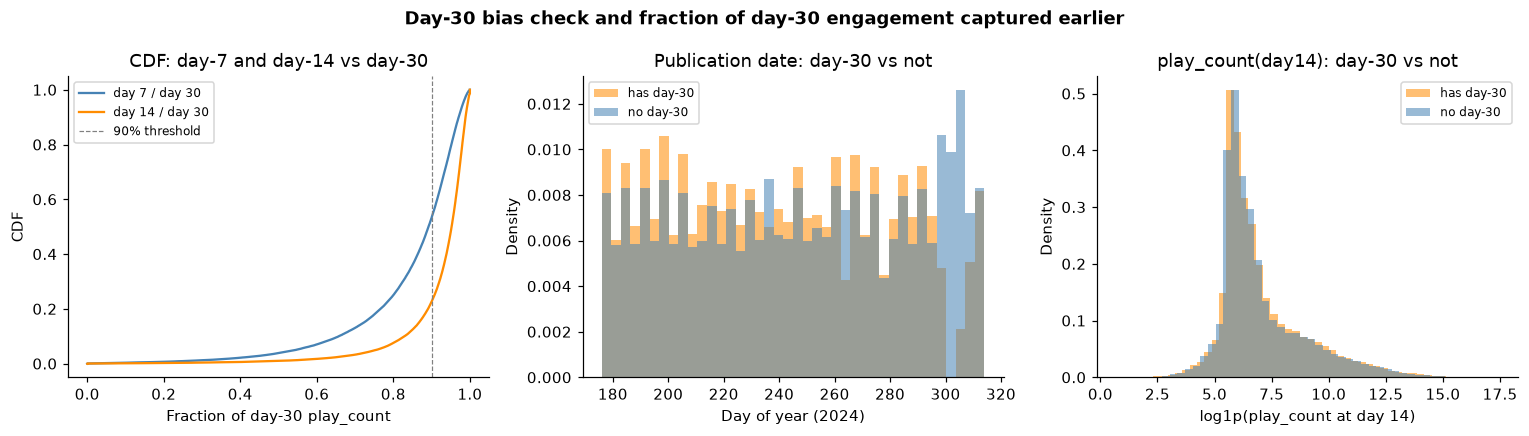

In [8]:
# Bias check: do day-30 videos differ systematically?
has30  = set(pc30.index)
v30    = videos[ videos["video_id"].isin(has30)].copy()
v_no30 = videos[~videos["video_id"].isin(has30)].copy()

for grp, label in [(v30, "has day-30"), (v_no30, "no day-30")]:
    s = pd.to_datetime(grp["create_date"], errors="coerce")
    pc14_grp = pc14.reindex(grp["video_id"]).dropna()
    print(f"{label} ({len(grp):,} videos): median create_date={s.median().date()}  "
          f"play_count(day14) median={pc14_grp.median():.0f}  mean={pc14_grp.mean():.0f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# CDF of ratios
for r, label, color in [(ratio7, "day 7 / day 30", "steelblue"),
                         (ratio14, "day 14 / day 30", "darkorange")]:
    rc = r.dropna().clip(0, 1)
    axes[0].plot(np.sort(rc), np.linspace(0, 1, len(rc)), label=label, color=color)
axes[0].axvline(0.9, color="gray", linestyle="--", linewidth=0.8, label="90% threshold")
axes[0].set_xlabel("Fraction of day-30 play_count"); axes[0].set_ylabel("CDF")
axes[0].set_title("CDF: day-7 and day-14 vs day-30"); axes[0].legend(fontsize=8)

# Bias: create_date
for grp, label, c in [(v30, "has day-30", "darkorange"), (v_no30, "no day-30", "steelblue")]:
    s = pd.to_datetime(grp["create_date"], errors="coerce")
    axes[1].hist(s.dt.dayofyear, bins=40, alpha=0.55, label=label, color=c, density=True)
axes[1].set_xlabel("Day of year (2024)"); axes[1].set_ylabel("Density")
axes[1].set_title("Publication date: day-30 vs not"); axes[1].legend(fontsize=8)

# Bias: play_count(day14)
for grp, label, c in [(v30, "has day-30", "darkorange"), (v_no30, "no day-30", "steelblue")]:
    pc_g = pc14.reindex(grp["video_id"]).dropna().clip(lower=1)
    axes[2].hist(np.log1p(pc_g), bins=50, alpha=0.55, label=label, color=c, density=True)
axes[2].set_xlabel("log1p(play_count at day 14)"); axes[2].set_ylabel("Density")
axes[2].set_title("play_count(day14): day-30 vs not"); axes[2].legend(fontsize=8)

fig.suptitle("Day-30 bias check and fraction of day-30 engagement captured earlier",
             fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "fig2_day30_ratio_and_bias.png", dpi=120)
plt.show()


## 4. Absolute vs relative target

In [9]:
min_vids = cfg["data"]["min_videos_per_creator"]
seed     = cfg["seed"]

vids_f   = filter_creators(videos, "author_id", min_videos=min_vids)
train_df, test_df = train_test_split_by_creator(vids_f, "author_id", test_size=0.2, seed=seed)
train_ids = set(train_df["video_id"])
test_ids  = set(test_df["video_id"])
print(f"Filtered (≥{min_vids} videos): {len(vids_f):,} videos  {vids_f['author_id'].nunique():,} creators")
print(f"Train: {len(train_df):,}  |  Test: {len(test_df):,}")


Filtered (≥30 videos): 201,832 videos  1,439 creators
Train: 161,465  |  Test: 40,367


In [10]:
abs_t = build_target(engagement, vids_f, day=14, mode="absolute")
rel_t = build_target(engagement, vids_f, day=14, mode="relative",
                     train_video_ids=train_ids)

for label, t in [("Absolute", abs_t), ("Relative", rel_t)]:
    print(f"{label}: n={len(t):,}  mean={t['target'].mean():.3f}"
          f"  std={t['target'].std():.3f}"
          f"  min={t['target'].min():.2f}  max={t['target'].max():.2f}")


Absolute: n=201,832  mean=7.021  std=1.895  min=0.00  max=17.45
Relative: n=201,832  mean=0.139  std=0.994  min=-10.19  max=9.20


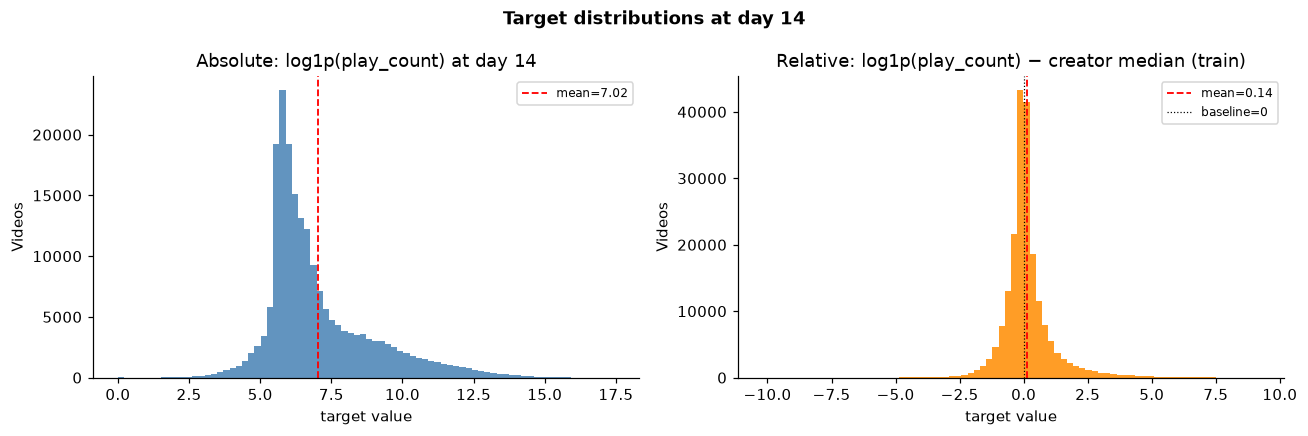

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, t, color, title in [
    (axes[0], abs_t, "steelblue",
     "Absolute: log1p(play_count) at day 14"),
    (axes[1], rel_t, "darkorange",
     "Relative: log1p(play_count) − creator median (train)"),
]:
    ax.hist(t["target"], bins=80, color=color, edgecolor="none", alpha=0.85)
    ax.axvline(t["target"].mean(), color="red", linewidth=1.2, linestyle="--",
               label=f"mean={t['target'].mean():.2f}")
    if color == "darkorange":
        ax.axvline(0, color="black", linewidth=0.8, linestyle=":", label="baseline=0")
    ax.set_xlabel("target value"); ax.set_ylabel("Videos")
    ax.set_title(title); ax.legend(fontsize=8)

fig.suptitle("Target distributions at day 14", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "fig3_target_distributions.png", dpi=120)
plt.show()


In [12]:
def _author_r2(target_df: pd.DataFrame) -> tuple[float, float]:
    """R² of 'predict per-author train mean' model on test set."""
    td = target_df.merge(vids_f[["video_id", "author_id"]], on="video_id", how="inner")
    tr = td[td["video_id"].isin(train_ids)]
    te = td[td["video_id"].isin(test_ids)].copy()
    author_means = tr.groupby("author_id")["target"].mean()
    te["pred"]   = te["author_id"].map(author_means).fillna(tr["target"].mean())
    ss_res = ((te["target"] - te["pred"]) ** 2).sum()
    ss_tot = ((te["target"] - te["target"].mean()) ** 2).sum()
    tr_pred = tr.copy()
    tr_pred["pred"] = tr_pred["author_id"].map(author_means)
    ss_res_tr = ((tr_pred["target"] - tr_pred["pred"]) ** 2).sum()
    ss_tot_tr = ((tr_pred["target"] - tr_pred["target"].mean()) ** 2).sum()
    return float(1 - ss_res_tr / ss_tot_tr), float(1 - ss_res / ss_tot)

r2_abs_tr, r2_abs_te = _author_r2(abs_t)
r2_rel_tr, r2_rel_te = _author_r2(rel_t)
print(f"R² (per-author mean model)  |  train  |  test")
print(f"  Absolute target            |  {r2_abs_tr:.3f}  |  {r2_abs_te:.3f}")
print(f"  Relative target            |  {r2_rel_tr:.3f}  |  {r2_rel_te:.3f}")
print(f"\n→ {r2_abs_te:.1%} of absolute-target variance is author_id alone.")
print(f"→ Relative target reduces this to {max(r2_rel_te,0):.1%}.")


R² (per-author mean model)  |  train  |  test
  Absolute target            |  0.739  |  0.732
  Relative target            |  0.046  |  0.044

→ 73.2% of absolute-target variance is author_id alone.
→ Relative target reduces this to 4.4%.


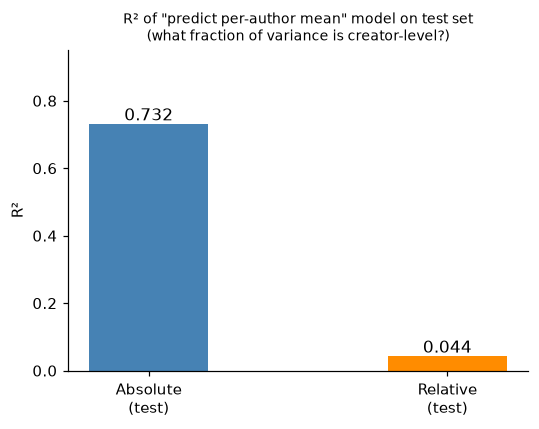

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))
labels  = ["Absolute\n(test)", "Relative\n(test)"]
heights = [r2_abs_te, max(r2_rel_te, 0)]
bars    = ax.bar(labels, heights, color=["steelblue", "darkorange"], width=0.4)
for bar, h in zip(bars, heights):
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.3f}",
            ha="center", fontsize=11)
ax.set_ylim(0, max(heights) * 1.3)
ax.set_ylabel("R²")
ax.set_title('R² of "predict per-author mean" model on test set\n'
             '(what fraction of variance is creator-level?)', fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "fig4_author_r2.png", dpi=120)
plt.show()


## 5. Follower count at publish time (as-of join)

In [14]:
videos_with_fc = follower_asof_join(videos, creator_daily)
cov = videos_with_fc["follower_count_at_publish"].notna().mean()
print(f"Coverage: {cov*100:.1f}%  ({videos_with_fc['follower_count_at_publish'].notna().sum():,} videos)")

joined = (abs_t
          .merge(videos_with_fc[["video_id", "follower_count_at_publish"]], on="video_id")
          .dropna(subset=["follower_count_at_publish"]))
joined["log_fc"] = np.log1p(joined["follower_count_at_publish"].clip(0))
pearson  = joined["log_fc"].corr(joined["target"])
spearman = joined["log_fc"].corr(joined["target"], method="spearman")
print(f"Pearson r  = {pearson:.3f}  (n={len(joined):,})")
print(f"Spearman ρ = {spearman:.3f}")


Coverage: 100.0%  (209,543 videos)


Pearson r  = 0.682  (n=201,832)
Spearman ρ = 0.645


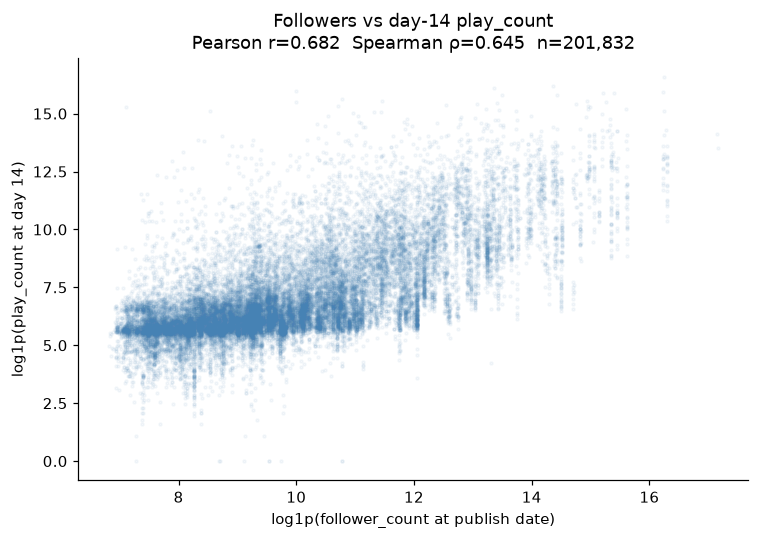

In [15]:
sample = joined.sample(min(30_000, len(joined)), random_state=42)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sample["log_fc"], sample["target"],
           alpha=0.05, s=4, color="steelblue", rasterized=True)
ax.set_xlabel("log1p(follower_count at publish date)")
ax.set_ylabel("log1p(play_count at day 14)")
ax.set_title(f"Followers vs day-14 play_count\n"
             f"Pearson r={pearson:.3f}  Spearman ρ={spearman:.3f}  n={len(joined):,}")
fig.tight_layout()
fig.savefig(FIGS / "fig5_follower_vs_target.png", dpi=120)
plt.show()
